In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Caminhos dos ficheiros
sales_path = os.path.join('..', '01_data', 'raw', 'retail_sales.csv')
abc_path = os.path.join('..', '01_data', 'processed', 'abc_xyz_classification.csv')

# Carregar dados
df_sales = pd.read_csv(sales_path)
df_sales['date'] = pd.to_datetime(df_sales['date'])
df_abc = pd.read_csv(abc_path)

print(f" Vendas carregadas: {df_sales.shape[0]:,} registros")
print(f" Classificação ABC/XYZ carregada: {df_abc.shape[0]} SKUs")
display(df_abc.head())

 Vendas carregadas: 4,565,000 registros
 Classificação ABC/XYZ carregada: 50 SKUs


,item_id,total_revenue,total_sales,mean_daily_sales,std_daily_sales,cv,cum_revenue,cum_perc,class_abc,class_xyz,matriz_abc_xyz
0,item_1,2.346581e+08,4207065,46.079573,15.162676,0.329054,2.346581e+08,0.033015,A,Y,AY
1,item_4,2.312873e+08,3964580,43.423658,14.314841,0.329655,4.659454e+08,0.065555,A,Y,AY
2,item_20,2.308357e+08,4261507,46.675871,15.274123,0.327238,6.967811e+08,0.098032,A,Y,AY
3,item_39,2.223552e+08,3938555,43.138609,14.221066,0.329660,9.191363e+08,0.129315,A,Y,AY
4,item_3,2.169482e+08,4108554,45.000591,14.842693,0.329833,1.136084e+09,0.159838,A,Y,AY


In [4]:
# Célula 2: Cálculo do Stock de Segurança e Ponto de Encomenda (ROP)

# 1. Mapeamento do Nível de Serviço (Z-Score) por Classe ABC
z_score_map = {
    'A': 1.65,  # 95% de nível de serviço (Baixo risco de rutura)
    'B': 1.28,  # 90% de nível de serviço
    'C': 1.04   # 85% de nível de serviço
}

df_abc['z_score'] = df_abc['class_abc'].map(z_score_map)

# 2. Atribuição determinística de Lead Time (dias) para simulação
# SKUs A têm fornecedores mais ágeis (7 dias), B (10 dias), C (14 dias)
lead_time_map = {'A': 7, 'B': 10, 'C': 14}
df_abc['lead_time_days'] = df_abc['class_abc'].map(lead_time_map)

# 3. Cálculo do Stock de Segurança (SS) e Ponto de Encomenda (ROP)
df_abc['safety_stock'] = np.ceil(
    df_abc['z_score'] * df_abc['std_daily_sales'] * np.sqrt(df_abc['lead_time_days'])
).astype(int)

df_abc['reorder_point'] = np.ceil(
    (df_abc['mean_daily_sales'] * df_abc['lead_time_days']) + df_abc['safety_stock']
).astype(int)

# 4. Guardar tabela dimensão enriquecida
output_dim_path = os.path.join('..', '01_data', 'processed', 'dim_products_inventory.csv')
df_abc.to_csv(output_dim_path, index=False)

print("=== PARÂMETROS DE ESTOQUE CALCULADOS COM SUCESSO ===")
display(df_abc[['item_id', 'class_abc', 'lead_time_days', 'mean_daily_sales', 'safety_stock', 'reorder_point']].head(10))

=== PARÂMETROS DE ESTOQUE CALCULADOS COM SUCESSO ===


,item_id,class_abc,lead_time_days,mean_daily_sales,safety_stock,reorder_point
0,item_1,A,7,46.079573,67,390
1,item_4,A,7,43.423658,63,367
2,item_20,A,7,46.675871,67,394
3,item_39,A,7,43.138609,63,365
4,item_3,A,7,45.000591,65,381
5,item_31,A,7,42.299025,61,358
6,item_6,A,7,44.374732,64,375
7,item_13,A,7,41.099179,60,348
8,item_2,A,7,39.172377,57,332
9,item_45,A,7,39.066824,57,331


     PAINEL DE MÉTRICAS DE PRECISÃO (HOLT-WINTERS)    
• Acurácia Global do Modelo:  92.45%
• MAPE (Erro Percentual):     7.55%
• MAE (Erro Absoluto Médio):  35,243 unidades/semana
• RMSE (Desvio Quadrático):   47,175 unidades/semana


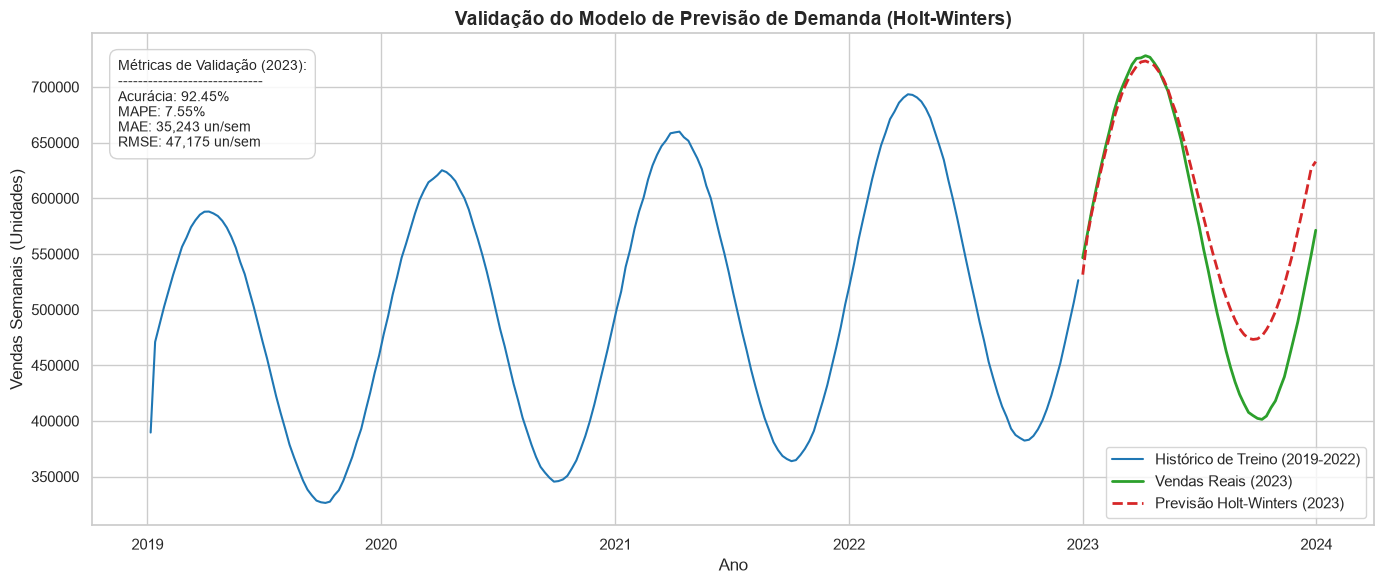

In [6]:
# Célula 3: Previsão de Demanda Global com Holt-Winters + Painel de Métricas
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. Agrupar vendas diárias totais e reamostrar semanalmente
daily_sales = df_sales.groupby('date')['sales'].sum().reset_index()
daily_sales = daily_sales.set_index('date').asfreq('D')
weekly_sales = daily_sales['sales'].resample('W').sum()

# 2. Separação Treino (2019 a 2022) vs Teste (2023)
train = weekly_sales[:'2022-12-31']
test = weekly_sales['2023-01-01':]

# 3. Treinamento do Modelo Preditivo (Tendência + Sazonalidade)
model = ExponentialSmoothing(
    train, 
    trend='add', 
    seasonal='add', 
    seasonal_periods=52
).fit()

# 4. Previsão para as 52 semanas de 2023
predictions = model.forecast(len(test))

# 5. Cálculo Estatístico das Métricas de Desempenho
mae = np.mean(np.abs(test - predictions))
rmse = np.sqrt(np.mean((test - predictions) ** 2))
mape = np.mean(np.abs((test - predictions) / test)) * 100
accuracy = 100 - mape

# Imprimir Resumo Executivo
print("=" * 48)
print("     PAINEL DE MÉTRICAS DE PRECISÃO (HOLT-WINTERS)    ")
print("=" * 48)
print(f"• Acurácia Global do Modelo:  {accuracy:.2f}%")
print(f"• MAPE (Erro Percentual):     {mape:.2f}%")
print(f"• MAE (Erro Absoluto Médio):  {mae:,.0f} unidades/semana")
print(f"• RMSE (Desvio Quadrático):   {rmse:,.0f} unidades/semana")
print("=" * 48)

# 6. Plotagem do Gráfico com Cartão de Métricas Incorporado
plt.figure(figsize=(14, 6))
plt.plot(train.index, train, label='Histórico de Treino (2019-2022)', color='#1f77b4', linewidth=1.5)
plt.plot(test.index, test, label='Vendas Reais (2023)', color='#2ca02c', linewidth=2)
plt.plot(test.index, predictions, label='Previsão Holt-Winters (2023)', color='#d62728', linestyle='--', linewidth=2)

# Adicionar caixa de texto com métricas dentro do gráfico
metrics_card = (
    f"Métricas de Validação (2023):\n"
    f"-----------------------------\n"
    f"Acurácia: {accuracy:.2f}%\n"
    f"MAPE: {mape:.2f}%\n"
    f"MAE: {mae:,.0f} un/sem\n"
    f"RMSE: {rmse:,.0f} un/sem"
)
plt.gca().text(
    0.02, 0.95, metrics_card, 
    transform=plt.gca().transAxes, 
    fontsize=10, 
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.6', facecolor='white', alpha=0.85, edgecolor='#cccccc')
)

plt.title('Validação do Modelo de Previsão de Demanda (Holt-Winters)', fontsize=14, fontweight='bold')
plt.ylabel('Vendas Semanais (Unidades)')
plt.xlabel('Ano')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [7]:
# Célula 4: Consolidação dos Resultados e Exportação para Power BI / Excel

# 1. Re-treinar o modelo com 100% dos dados históricos (2019 a 2023) para projetar 2024
full_model = ExponentialSmoothing(
    weekly_sales, 
    trend='add', 
    seasonal='add', 
    seasonal_periods=52
).fit()

# 2. Projetar a procura para as 52 semanas de 2024
forecast_2024 = full_model.forecast(52)

# 3. Criar DataFrame de Previsão Semanal
df_forecast = pd.DataFrame({
    'date': forecast_2024.index,
    'predicted_weekly_sales': np.round(forecast_2024.values)
})

# 4. Exportar Ficheiro Consolidado de Previsão Global
forecast_output_path = os.path.join('..', '01_data', 'processed', 'fact_weekly_demand_forecast.csv')
df_forecast.to_csv(forecast_output_path, index=False)

print("=== EXPORTAÇÃO CONCLUÍDA COM SUCESSO ===")
print(f"Ficheiro guardado em: {forecast_output_path}")
print(f"Total de semanas projetadas para 2024: {len(df_forecast)}")
display(df_forecast.head(10))

=== EXPORTAÇÃO CONCLUÍDA COM SUCESSO ===
Ficheiro guardado em: ..\01_data\processed\fact_weekly_demand_forecast.csv
Total de semanas projetadas para 2024: 52


,date,predicted_weekly_sales
0,2024-01-07,599521.0
1,2024-01-14,622736.0
2,2024-01-21,643459.0
3,2024-01-28,664620.0
4,2024-02-04,684224.0
5,2024-02-11,702520.0
6,2024-02-18,721680.0
7,2024-02-25,737301.0
8,2024-03-03,751677.0
9,2024-03-10,763353.0
